In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from statsmodels.graphics.tsaplots import plot_acf

In [2]:
DATA_DIR = Path(r"C:/Users/sarp2/Desktop/Data Science/bike+sharing+dataset")

In [3]:
day_df = pd.read_csv(DATA_DIR / "data/day.csv")
hour_df = pd.read_csv(DATA_DIR / "data/hour.csv")

day = day_df.copy()
hour = hour_df.copy()

In [4]:
day.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [5]:
hour.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [6]:
day.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 91.5 KB


In [7]:
day["dteday"] = pd.to_datetime(day["dteday"])

In [8]:
sum(day["dteday"] == pd.date_range(day["dteday"][0], day["dteday"][730]))

731

In [9]:
day["cnt_rolling7"] = day["cnt"].rolling(window=7).mean()
day["casual_rolling7"] = day["casual"].rolling(window=7).mean()
day["registered_rolling7"] = day["registered"].rolling(window=7).mean()

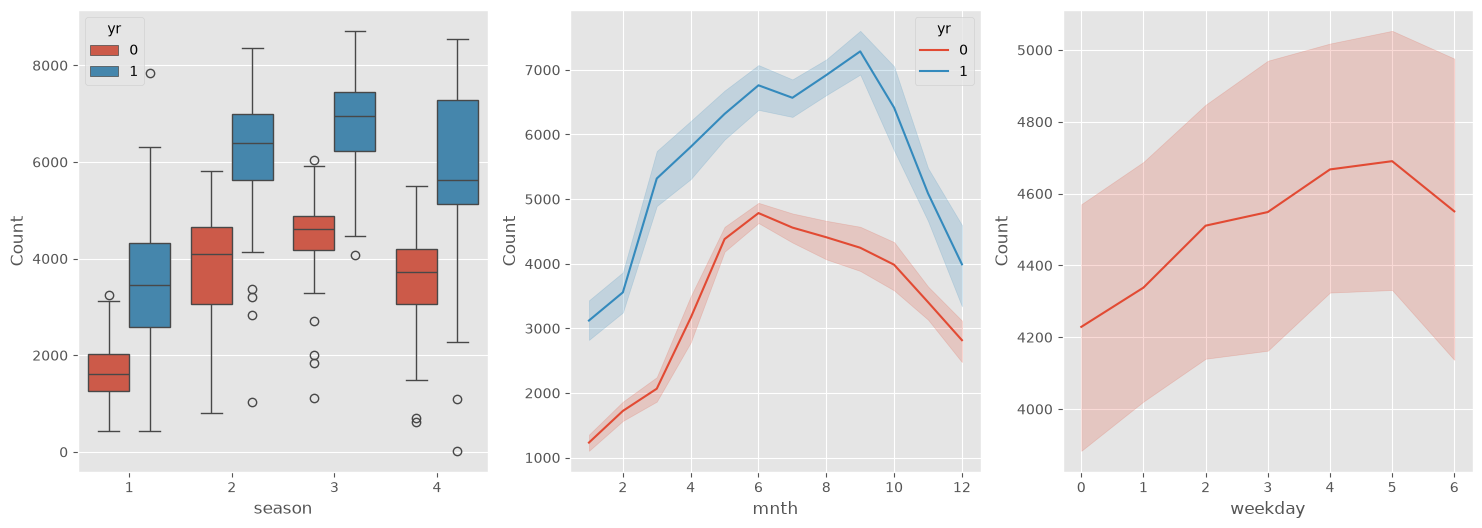

In [10]:
plt.style.use("ggplot")

fig, ax = plt.subplots(1,3,figsize=(18,6))
ax = ax.flatten()

sns.boxplot(data=day, x="season", y="cnt", ax=ax[0], hue="yr")
ax[0].set_ylabel("Count")

sns.lineplot(data=day, x="mnth", y="cnt", ax=ax[1], hue="yr")
ax[1].set_ylabel("Count")

sns.lineplot(data=day, x="weekday", y="cnt", ax=ax[2])
ax[2].set_ylabel("Count")

plt.show()

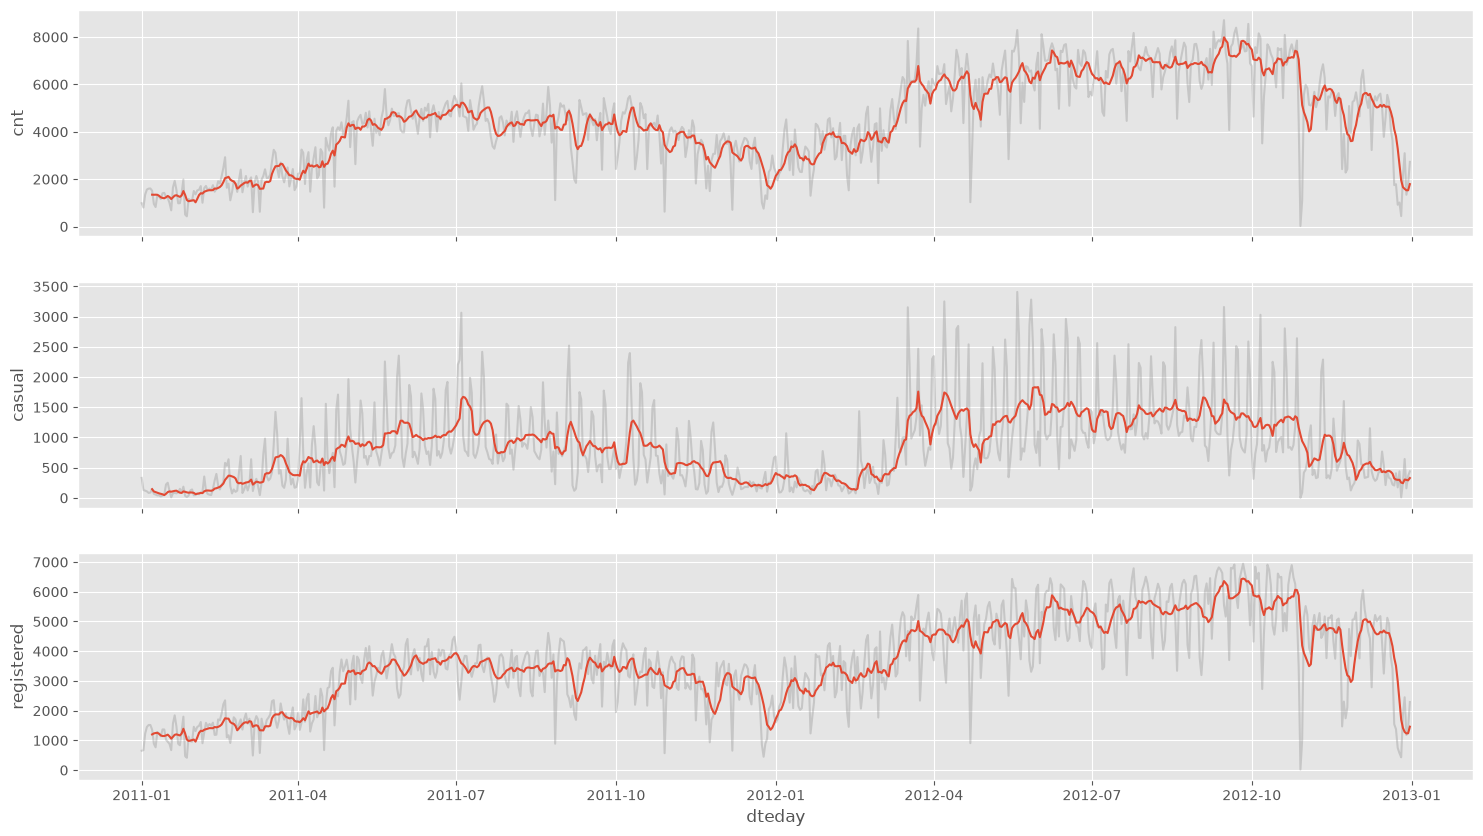

In [11]:
fig, ax = plt.subplots(3, 1, figsize=(18,10), sharex=True)
ax = ax.flatten()

sns.lineplot(data=day, x="dteday", y="cnt", ax=ax[0], alpha=0.3, color="gray")
sns.lineplot(data=day, x="dteday", y="cnt_rolling7", ax=ax[0])

sns.lineplot(data=day, x="dteday", y="casual", ax=ax[1], alpha=0.3, color="gray")
sns.lineplot(data=day, x="dteday", y="casual_rolling7", ax=ax[1])

sns.lineplot(data=day, x="dteday", y="registered", ax=ax[2], alpha=0.3, color="gray")
sns.lineplot(data=day, x="dteday", y="registered_rolling7", ax=ax[2])

plt.show()

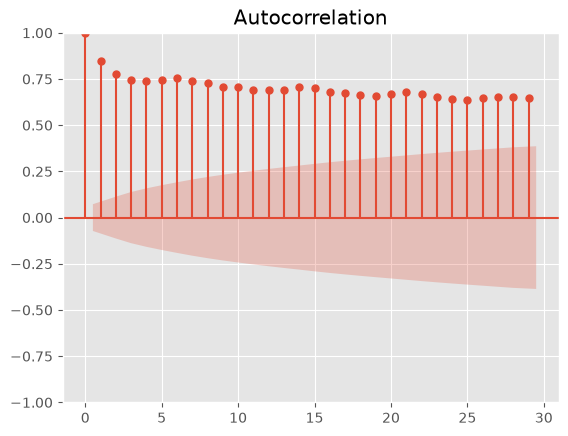

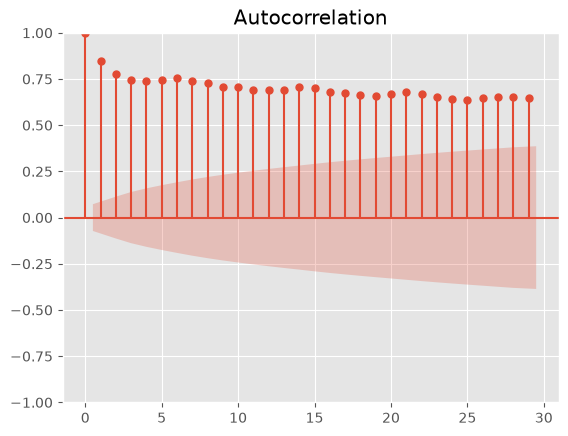

In [12]:
plot_acf(x=day["cnt"])

<Axes: >

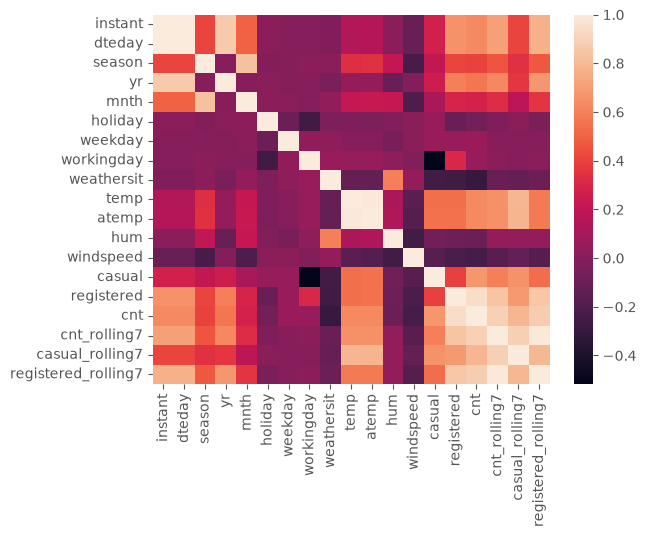

In [13]:
sns.heatmap(day.corr())

In [14]:
day.corr()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,cnt_rolling7,casual_rolling7,registered_rolling7
instant,1.000000,1.000000,0.412224,0.866025,0.496702,0.016145,-0.000016,-0.004337,-0.021477,0.150580,0.152638,0.016375,-0.112620,0.275255,0.659623,0.628830,0.707416,0.411459,0.770887
dteday,1.000000,1.000000,0.412224,0.866025,0.496702,0.016145,-0.000016,-0.004337,-0.021477,0.150580,0.152638,0.016375,-0.112620,0.275255,0.659623,0.628830,0.707416,0.411459,0.770887
season,0.412224,0.412224,1.000000,-0.001844,0.831440,-0.010537,-0.003080,0.012485,0.019211,0.334315,0.342876,0.205445,-0.229046,0.210399,0.411623,0.406100,0.455721,0.342636,0.469962
yr,0.866025,0.866025,-0.001844,1.000000,-0.001792,0.007954,-0.005461,-0.002013,-0.048727,0.047604,0.046106,-0.110651,-0.011817,0.248546,0.594248,0.566710,0.623387,0.361701,0.679622
mnth,0.496702,0.496702,0.831440,-0.001792,1.000000,0.019191,0.009509,-0.005901,0.043528,0.220205,0.227459,0.222204,-0.207502,0.123006,0.293488,0.279977,0.329524,0.193115,0.358591
holiday,0.016145,0.016145,-0.010537,0.007954,0.019191,1.000000,-0.101960,-0.253023,-0.034627,-0.028556,-0.032507,-0.015937,0.006292,0.054274,-0.108745,-0.068348,-0.031638,0.006736,-0.043112
weekday,-0.000016,-0.000016,-0.003080,-0.005461,0.009509,-0.101960,1.000000,0.035790,0.031087,-0.000170,-0.007537,-0.052232,0.014282,0.059923,0.057367,0.067443,-0.000514,-0.000291,-0.000563
workingday,-0.004337,-0.004337,0.012485,-0.002013,-0.005901,-0.253023,0.035790,1.000000,0.061200,0.052660,0.052182,0.024327,-0.018796,-0.518044,0.303907,0.061156,0.015640,0.001179,0.019762
weathersit,-0.021477,-0.021477,0.019211,-0.048727,0.043528,-0.034627,0.031087,0.061200,1.000000,-0.120602,-0.121583,0.591045,0.039511,-0.247353,-0.260388,-0.297391,-0.107246,-0.120086,-0.097044
temp,0.150580,0.150580,0.334315,0.047604,0.220205,-0.028556,-0.000170,0.052660,-0.120602,1.000000,0.991702,0.126963,-0.157944,0.543285,0.540012,0.627494,0.654619,0.786703,0.573903


In [15]:
hour.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [16]:
hour["weathersit"].describe()

count    17379.000000
mean         1.425283
std          0.639357
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max          4.000000
Name: weathersit, dtype: float64

In [17]:
hour.groupby("dteday")["atemp"].agg(["min", "max"])

,min,max
dteday,,
2011-01-01,0.2576,0.4545
2011-01-02,0.2121,0.4545
2011-01-03,0.1061,0.2576
2011-01-04,0.1364,0.2879
2011-01-05,0.1818,0.3182
...,...,...
2012-12-27,0.1970,0.2727
2012-12-28,0.2121,0.3182
2012-12-29,0.2424,0.2424


In [18]:
bad_weather = list(hour[(hour["hr"]>=17) & (hour["hr"]<=19) & (hour["weathersit"].isin([3,4]))].index)

In [19]:
hour.loc[bad_weather, "rush_hour_bad_weather"] = int(1)
hour["rush_hour_bad_weather"] = hour["rush_hour_bad_weather"].fillna(int(0))

In [20]:
hour.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,rush_hour_bad_weather
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,0.0
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,0.0
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,0.0
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,0.0
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,0.0


In [21]:
hour["dteday"] = pd.to_datetime(hour["dteday"])

In [22]:
rush_hour_bad_weather = hour.groupby("dteday")["rush_hour_bad_weather"].max()

In [23]:
day.merge(rush_hour_bad_weather, how="left", on="dteday")

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,cnt_rolling7,casual_rolling7,registered_rolling7,rush_hour_bad_weather
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985,NaN,NaN,NaN,1.0
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801,NaN,NaN,NaN,0.0
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349,NaN,NaN,NaN,0.0
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562,NaN,NaN,NaN,0.0
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600,NaN,NaN,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,727,2012-12-27,1,1,12,0,4,1,2,0.254167,0.226642,0.652917,0.350133,247,1867,2114,1663.857143,243.428571,1420.428571,0.0
727,728,2012-12-28,1,1,12,0,5,1,2,0.253333,0.255046,0.590000,0.155471,644,2451,3095,1588.428571,303.857143,1284.571429,0.0
728,729,2012-12-29,1,1,12,0,6,0,2,0.253333,0.242400,0.752917,0.124383,159,1182,1341,1530.142857,297.285714,1232.857143,0.0
729,730,2012-12-30,1,1,12,0,0,0,1,0.255833,0.231700,0.483333,0.350754,364,1432,1796,1531.428571,291.000000,1240.428571,0.0


In [24]:
day.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,cnt_rolling7,casual_rolling7,registered_rolling7
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985,NaN,NaN,NaN
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801,NaN,NaN,NaN
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349,NaN,NaN,NaN
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562,NaN,NaN,NaN
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600,NaN,NaN,NaN


In [25]:
day.describe()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,cnt_rolling7,casual_rolling7,registered_rolling7
count,731.000000,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,725.000000,725.000000,725.000000
mean,366.000000,2012-01-01 00:00:00,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837,4527.936552,852.984631,3674.951921
min,1.000000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000,1022.714286,46.142857,960.000000
25%,183.500000,2011-07-02 12:00:00,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000,3344.000000,412.000000,2926.428571
50%,366.000000,2012-01-01 00:00:00,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000,4470.142857,876.285714,3502.571429
75%,548.500000,2012-07-01 12:00:00,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000,6123.000000,1268.714286,4792.428571
max,731.000000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000,7988.000000,1833.857143,6444.000000
std,211.165812,NaN,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452,1740.978997,463.773876,1350.098356


In [27]:
hour.groupby("dteday")["windspeed"].max()

dteday
2011-01-01    0.2985
2011-01-02    0.4478
2011-01-03    0.4179
2011-01-04    0.3284
2011-01-05    0.3284
               ...  
2012-12-27    0.5224
2012-12-28    0.2836
2012-12-29    0.5522
2012-12-30    0.6567
2012-12-31    0.2239
Name: windspeed, Length: 731, dtype: float64